# S01 Solar Power Day-Ahead Forecasting
# Proposal Stage: Data Loading, EDA, and Preprocessing

**Plant:** S01 (anonymized identifier)  
**Installed capacity:** 6.00 MW (6,000 kW)  
**Data source:** Provincial Electricity Authority (PEA)  
**Study period:** 2023–2024  
**Original resolution:** 5 minutes  
**Forecast resolution:** 15 minutes  
**Forecast horizon:** Day-ahead, 96 intervals per day

This notebook covers the data loading, exploratory data analysis (EDA), and preprocessing stages of our solar power forecasting project. The goal is to understand the characteristics and quality of the S01 dataset before proceeding to model development.

The following steps are covered in this notebook:

1. Data Loading
2. Exploratory Data Analysis
3. Data Preprocessing


## 0. Setup


The S01 dataset is organized in the following folder structure:

```text
solar-forecasting-s01/
├── data/                              ← local only, gitignored
│   └── S01/
│       ├── 2023/
│       │   ├── S01-01-23.xlsx
│       │   └── ...
│       └── 2024/
│           ├── S01-01-24.xlsx
│           └── ...
├── notebooks/
│   └── S01_Solar_DayAhead_Forecasting_Proposal.ipynb
├── docs/
│   ├── S01_Data_Quality_Issues_Log_v2.docx
│   ├── Solar_Power_Generation_Forecasting_Proposal.pdf
│   └── Solar_Power_Generation_Forecasting_Presentation_Slide.pdf
├── outputs/                           ← generated figures and tables
├── src/                               ← helper .py modules later
├── .gitignore
└── README.md
```

Raw PEA Excel files are stored locally in `data/` and excluded from version control. All generated outputs (figures, tables, CSVs) are saved to `outputs/`.
```

The code uses `Path.home()` so it works across different machines without hardcoding the username.

In [1]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install nbstripout


Note: you may need to restart the kernel to use updated packages.


In [ ]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

PLANT_CAPACITY_KW = 6000
STEPS_PER_DAY = 96
RANDOM_STATE = 42

# === Paths ===
REPO_ROOT = Path("C:/Users/Admin/solar-forecasting-s01")

# Raw PEA Excel files (local only, gitignored)
DATA_ROOT = REPO_ROOT / "data" / "S01"
YEAR_FOLDERS = [DATA_ROOT / "2023", DATA_ROOT / "2024"]

# Cache file (speeds up reloading)
CACHE_FILE = REPO_ROOT / "data" / "S01_2023_2024_5min_cache_v2.csv"

# All figures and tables go here (tracked by git)
OUTPUT_DIR = REPO_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("DATA_ROOT:", DATA_ROOT)
print("CACHE_FILE:", CACHE_FILE)
print("OUTPUT_DIR:", OUTPUT_DIR)

# 1. Data Loading

Each monthly Excel workbook from PEA contains one worksheet per day, with measurements recorded at 5-minute intervals. We read all 24 workbooks (12 months × 2 years), extract the date from the worksheet name and the month/year from cell A1, and combine them into a single continuous dataset.

In [ ]:
# List all monthly Excel files from 2023 and 2024
excel_files = []

for folder in YEAR_FOLDERS:
    files = sorted(folder.glob("S01-*.xlsx"))
    excel_files.extend(files)
    print(f"{folder.name}: {len(files)} file(s)")

print("\nTotal Excel files:", len(excel_files))

if len(excel_files) == 0:
    raise FileNotFoundError(
        "No Excel files were found. Check DATA_ROOT and the 2023/2024 folder names."
    )

display(pd.DataFrame({
    "file": [f.name for f in excel_files],
    "folder": [f.parent.name for f in excel_files]
}))

2023: 12 file(s)
2024: 12 file(s)

Total Excel files: 24


,file,folder
0,S01-01-23.xlsx,2023
1,S01-02-23.xlsx,2023
2,S01-03-23.xlsx,2023
3,S01-04-23.xlsx,2023
4,S01-05-23.xlsx,2023
5,S01-06-23.xlsx,2023
6,S01-07-23.xlsx,2023
7,S01-08-23.xlsx,2023
8,S01-09-23.xlsx,2023
9,S01-10-23.xlsx,2023


In [ ]:
import re

def read_month_workbook(file_path):
    """Read one monthly S01 workbook and return combined daily data.

    The month and year are taken from the FILE NAME (e.g. S01-03-23.xlsx),
    not from cell A1. In the PEA workbooks A1 is only filled on some sheets
    and sometimes holds a stale date (e.g. 2022 inside a 2023 file), which
    previously caused most days to be skipped or mis-dated.
    """

    match = re.search(r"S01-(\d{2})-(\d{2})", Path(file_path).stem)
    if match is None:
        return pd.DataFrame()

    file_month = int(match.group(1))
    file_year = 2000 + int(match.group(2))

    xls = pd.ExcelFile(file_path, engine="openpyxl")
    daily_frames = []

    for sheet in xls.sheet_names:

        # Sheet names should be day numbers such as 1, 2, ..., 31
        try:
            day = int(str(sheet).strip())
        except ValueError:
            continue

        # Build the real date from the file name + sheet (day) name
        try:
            current_date = pd.Timestamp(year=file_year, month=file_month, day=day)
        except ValueError:
            # Example: sheet 31 in a month with only 30 days
            continue

        raw = xls.parse(sheet, header=None)

        # Expected file structure requires at least 4 rows and 9 columns
        if raw.shape[0] < 4 or raw.shape[1] < 9:
            continue

        # Actual measurements start from row 4 and columns B:I
        temp = raw.iloc[3:, 1:9].copy()

        temp.columns = [
            "time",
            "PVTEMP1",
            "PVTEMP2",
            "AMBTEMP",
            "PYRANO1",
            "PYRANO2",
            "WINDSPEED",
            "P"
        ]

        temp = temp.dropna(subset=["time"])

        # Convert sensor columns to numeric
        numeric_cols = [
            "PVTEMP1", "PVTEMP2", "AMBTEMP",
            "PYRANO1", "PYRANO2", "WINDSPEED", "P"
        ]

        for col in numeric_cols:
            temp[col] = pd.to_numeric(temp[col], errors="coerce")

        # Combine date + time
        def combine_date_time(t):
            try:
                if isinstance(t, pd.Timestamp):
                    t = t.time()
                elif not hasattr(t, "hour"):
                    t = pd.to_datetime(str(t)).time()

                return pd.Timestamp.combine(current_date.date(), t)
            except Exception:
                return pd.NaT

        temp["timestamp"] = temp["time"].apply(combine_date_time)
        temp = temp.dropna(subset=["timestamp"])

        temp = temp[["timestamp"] + numeric_cols]

        daily_frames.append(temp)

    if not daily_frames:
        return pd.DataFrame()

    return pd.concat(daily_frames, ignore_index=True)

### Load all monthly workbooks

Reading 24 Excel workbooks with many worksheets takes some time. A CSV cache is saved after the first successful load so that subsequent runs are faster.

To force a fresh reload from the original Excel files, set `USE_CACHE = False`.

**Note:** the cache file is versioned (`_v2`). The loader now derives the month/year from the file name instead of cell A1, which fixed ~178 days that were previously skipped or mis-dated. Delete any older cache file and re-run all cells below.

In [ ]:
CACHE_FILE = DATA_ROOT / "S01_2023_2024_5min_cache_v2.csv"
USE_CACHE = True

if USE_CACHE and CACHE_FILE.exists():
    print("Loading cached dataset:", CACHE_FILE)
    df_raw = pd.read_csv(CACHE_FILE, parse_dates=["timestamp"])

else:
    all_months = []

    for i, file in enumerate(excel_files, start=1):
        print(f"[{i}/{len(excel_files)}] Loading {file.name} ...")

        month_df = read_month_workbook(file)

        if not month_df.empty:
            all_months.append(month_df)

    if not all_months:
        raise ValueError("The workbooks were found, but no usable measurement data were loaded.")

    df_raw = pd.concat(all_months, ignore_index=True)
    df_raw = df_raw.sort_values("timestamp").reset_index(drop=True)

    df_raw.to_csv(CACHE_FILE, index=False)
    print("\nCache saved to:", CACHE_FILE)

# Keep only the intended study years
df_raw = df_raw[
    df_raw["timestamp"].dt.year.isin([2023, 2024])
].copy()

df_raw = df_raw.sort_values("timestamp").reset_index(drop=True)

# Sanity check: 2023-2024 has 731 calendar days
n_days = df_raw["timestamp"].dt.date.nunique()
print("Unique days loaded:", n_days, "(expected 731)")

print("Shape:", df_raw.shape)
print("Start:", df_raw["timestamp"].min())
print("End:", df_raw["timestamp"].max())

display(df_raw.head())

Loading cached dataset: C:\Users\Admin\solar-forecasting-s01\data\S01\S01_2023_2024_5min_cache_v2.csv
Unique days loaded: 731 (expected 731)
Shape: (210528, 8)
Start: 2023-01-01 00:00:00
End: 2024-12-31 23:55:00


,timestamp,PVTEMP1,PVTEMP2,AMBTEMP,PYRANO1,PYRANO2,WINDSPEED,P
0,2023-01-01 00:00:00,20.39,20.70,21.13,0.60,0.42,3.58,0.0
1,2023-01-01 00:05:00,20.28,20.61,21.04,0.61,0.41,3.76,0.0
2,2023-01-01 00:10:00,20.24,20.59,20.95,0.61,0.42,3.71,0.0
3,2023-01-01 00:15:00,20.06,20.38,20.82,0.61,0.41,2.82,0.0
4,2023-01-01 00:20:00,19.89,20.21,20.77,0.61,0.42,3.31,0.0


# 2. Exploratory Data Analysis

We perform EDA to understand the characteristics and quality of the S01 dataset before model development. The analysis covers data coverage, missing values, descriptive statistics, temporal patterns, variable distributions, and correlations. These results form the basis of the Preliminary Results section in the proposal.

## 2.1 Dataset Structure and Coverage


In [ ]:
print("Dataset information")
print("-" * 50)
print("Rows:", f"{len(df_raw):,}")
print("Columns:", df_raw.shape[1])
print("Start:", df_raw["timestamp"].min())
print("End:", df_raw["timestamp"].max())
print("Duplicate timestamps:", df_raw["timestamp"].duplicated().sum())

expected_5min = pd.Timedelta(minutes=5)
time_diff = df_raw["timestamp"].diff()

print("\nMost common time intervals:")
display(time_diff.value_counts().head(10).to_frame("count"))

print("\nData types:")
display(df_raw.dtypes.to_frame("dtype"))

Dataset information
--------------------------------------------------
Rows: 210,528
Columns: 8
Start: 2023-01-01 00:00:00
End: 2024-12-31 23:55:00
Duplicate timestamps: 0

Most common time intervals:


,count
timestamp,
0 days 00:05:00,210527



Data types:


,dtype
timestamp,datetime64[ns]
PVTEMP1,float64
PVTEMP2,float64
AMBTEMP,float64
PYRANO1,float64
PYRANO2,float64
WINDSPEED,float64
P,float64


In [ ]:
from calendar import monthrange

# ── Coverage by year and month (fixed denominator) ──
coverage = (
    df_raw
    .assign(
        year=df_raw["timestamp"].dt.year,
        month=df_raw["timestamp"].dt.month,
        date=df_raw["timestamp"].dt.date
    )
    .groupby(["year", "month"])
    .agg(
        rows=("timestamp", "size"),
        days_present=("date", "nunique"),
        first_timestamp=("timestamp", "min"),
        last_timestamp=("timestamp", "max")
    )
    .reset_index()
)

# Fixed: use calendar days, not days_present
coverage["calendar_days"] = coverage.apply(
    lambda r: monthrange(int(r["year"]), int(r["month"]))[1], axis=1
)
coverage["missing_days"] = coverage["calendar_days"] - coverage["days_present"]
coverage["expected_5min_rows"] = coverage["calendar_days"] * 288
coverage["coverage_%"] = (
    coverage["rows"] / coverage["expected_5min_rows"] * 100
).round(2)

print("Monthly Data Coverage (denominator = calendar days × 288)")
print("=" * 60)
display(coverage)

total_calendar = coverage["calendar_days"].sum()
total_present = coverage["days_present"].sum()
total_missing = coverage["missing_days"].sum()
print(f"\nTotal: {total_present} of {total_calendar} calendar days present "
      f"({total_missing} missing)")

coverage.to_csv(
    OUTPUT_DIR / "table_01_monthly_data_coverage.csv",
    index=False
)

,year,month,rows,days_present,first_timestamp,last_timestamp,expected_5min_rows,coverage_%
0,2023,1,8928,31,2023-01-01,2023-01-31 23:55:00,8928,100.0
1,2023,2,8064,28,2023-02-01,2023-02-28 23:55:00,8064,100.0
2,2023,3,8928,31,2023-03-01,2023-03-31 23:55:00,8928,100.0
3,2023,4,8640,30,2023-04-01,2023-04-30 23:55:00,8640,100.0
4,2023,5,8928,31,2023-05-01,2023-05-31 23:55:00,8928,100.0
5,2023,6,8640,30,2023-06-01,2023-06-30 23:55:00,8640,100.0
6,2023,7,8928,31,2023-07-01,2023-07-31 23:55:00,8928,100.0
7,2023,8,8928,31,2023-08-01,2023-08-31 23:55:00,8928,100.0
8,2023,9,8640,30,2023-09-01,2023-09-30 23:55:00,8640,100.0
9,2023,10,8928,31,2023-10-01,2023-10-31 23:55:00,8928,100.0


## 2.2 Missing Values


In [ ]:
sensor_cols = [
    "PVTEMP1",
    "PVTEMP2",
    "AMBTEMP",
    "PYRANO1",
    "PYRANO2",
    "WINDSPEED",
    "P"
]

missing_table = pd.DataFrame({
    "missing_count": df_raw[sensor_cols].isna().sum(),
    "missing_%": (df_raw[sensor_cols].isna().mean() * 100).round(4)
}).sort_values("missing_%", ascending=False)

display(missing_table)

missing_table.to_csv(
    OUTPUT_DIR / "table_02_missing_values.csv"
)

,missing_count,missing_%
P,335,0.1591
PVTEMP2,117,0.0556
PVTEMP1,117,0.0556
AMBTEMP,117,0.0556
PYRANO1,117,0.0556
PYRANO2,117,0.0556
WINDSPEED,117,0.0556


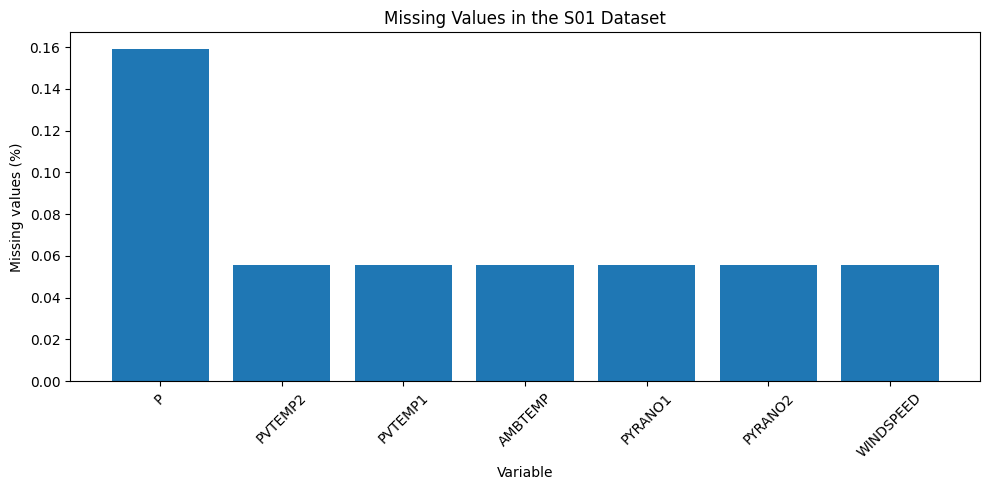

In [ ]:
# Visualize missing values across all sensor variables
plt.figure(figsize=(10, 5))
plt.bar(missing_table.index, missing_table["missing_%"])
plt.ylabel("Missing values (%)")
plt.xlabel("Variable")
plt.title("Missing Values in the S01 Dataset")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_01_missing_values.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 2.3 Descriptive Statistics


In [ ]:
descriptive_stats = df_raw[sensor_cols].describe().T
descriptive_stats["missing"] = df_raw[sensor_cols].isna().sum()

display(descriptive_stats)

descriptive_stats.to_csv(
    OUTPUT_DIR / "table_03_descriptive_statistics.csv"
)

,count,mean,std,min,25%,50%,75%,max,missing
PVTEMP1,210411.0,33.536977,12.900306,0.00,24.464970,27.000000,42.623817,77.32,117
PVTEMP2,210411.0,33.663820,12.733954,0.00,24.696054,27.184992,42.651981,76.22,117
AMBTEMP,210411.0,28.369712,6.147621,0.00,25.010000,27.470000,31.920000,50.00,117
PYRANO1,210411.0,230.669022,324.479681,0.00,0.552991,4.570449,430.260000,1343.13,117
PYRANO2,210411.0,229.712003,323.382608,0.00,0.463939,3.870000,431.615000,1354.31,117
WINDSPEED,210411.0,7.567913,17.770772,0.00,0.773432,1.640000,2.673762,60.00,117
P,210193.0,1067.963720,1500.236386,-6.82,0.000000,0.000000,2114.770000,5552.26,335


## 2.4 Time-Series Visualization

A sample week of 5-minute power generation data is shown to illustrate the daily solar cycle present in the dataset.

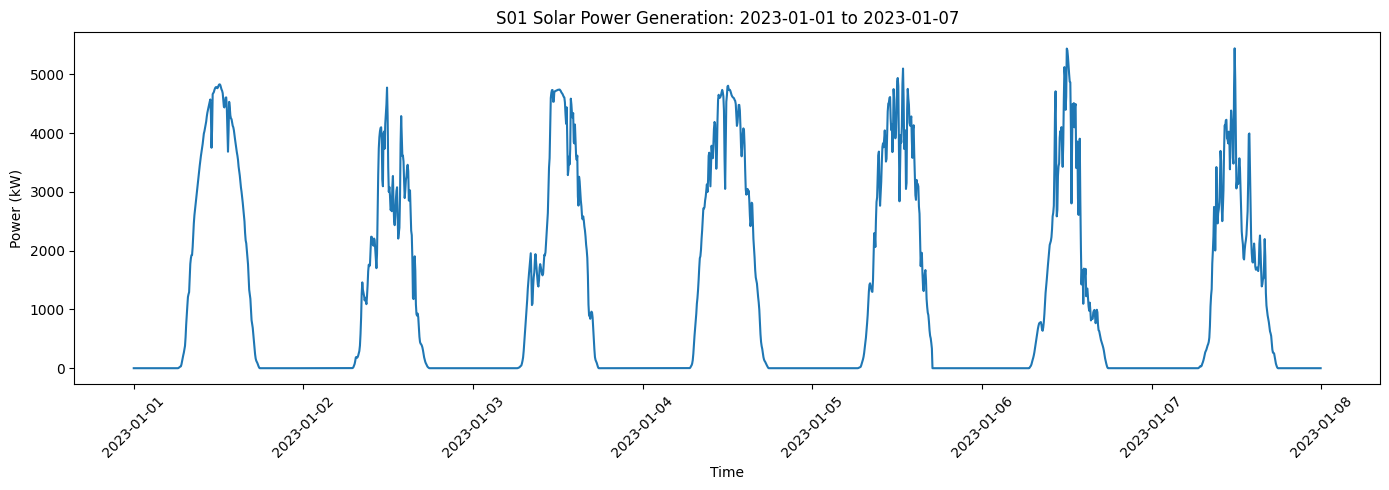

In [ ]:
# Automatically select the first 7 complete calendar days available
plot_start = df_raw["timestamp"].min().normalize()
plot_end = plot_start + pd.Timedelta(days=7)

sample_week = df_raw[
    (df_raw["timestamp"] >= plot_start) &
    (df_raw["timestamp"] < plot_end)
]

plt.figure(figsize=(14, 5))
plt.plot(sample_week["timestamp"], sample_week["P"])
plt.xlabel("Time")
plt.ylabel("Power (kW)")
plt.title(f"S01 Solar Power Generation: {plot_start.date()} to {(plot_end - pd.Timedelta(days=1)).date()}")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_02_power_timeseries_sample_week.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 2.5 Mean Daily Solar Power Profile

The mean power at each time of day is computed separately for 2023 and 2024 to observe the typical daily generation pattern and any year-to-year differences.

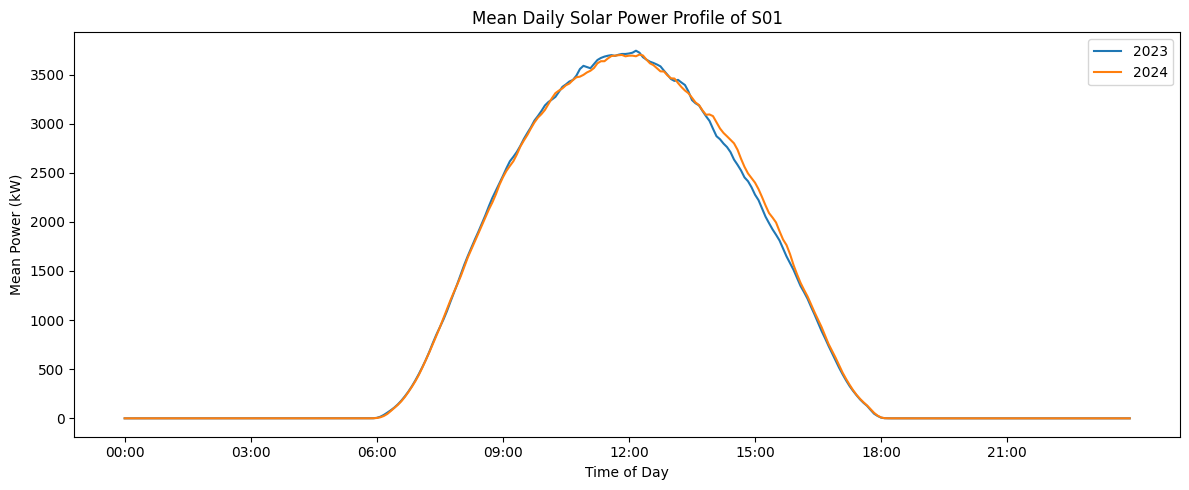

In [ ]:
eda_profile = df_raw.copy()

eda_profile["year"] = eda_profile["timestamp"].dt.year
eda_profile["time_of_day"] = eda_profile["timestamp"].dt.strftime("%H:%M")

daily_profile = (
    eda_profile
    .groupby(["year", "time_of_day"], as_index=False)["P"]
    .mean()
)

plt.figure(figsize=(12, 5))

for year in sorted(daily_profile["year"].unique()):
    temp = daily_profile[daily_profile["year"] == year]
    plt.plot(
        np.arange(len(temp)),
        temp["P"],
        label=str(year)
    )

# Tick every 3 hours = 36 samples at 5-min resolution
tick_positions = np.arange(0, 288, 36)
tick_labels = [f"{h:02d}:00" for h in range(0, 24, 3)]

plt.xticks(tick_positions, tick_labels)
plt.xlabel("Time of Day")
plt.ylabel("Mean Power (kW)")
plt.title("Mean Daily Solar Power Profile of S01")
plt.legend()
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_03_mean_daily_power_profile.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 2.6 Monthly Energy Pattern

Since power (P) is recorded in kW at 5-minute intervals, the approximate energy for each record is P × (5/60) kWh. Monthly totals show the seasonal variation across the two study years.

,month,energy_MWh
0,2023-01,841.240683
1,2023-02,811.477403
2,2023-03,891.831515
3,2023-04,762.335183
4,2023-05,780.531861
5,2023-06,699.891669
6,2023-07,719.104003
7,2023-08,753.957314
8,2023-09,619.757566
9,2023-10,753.160565


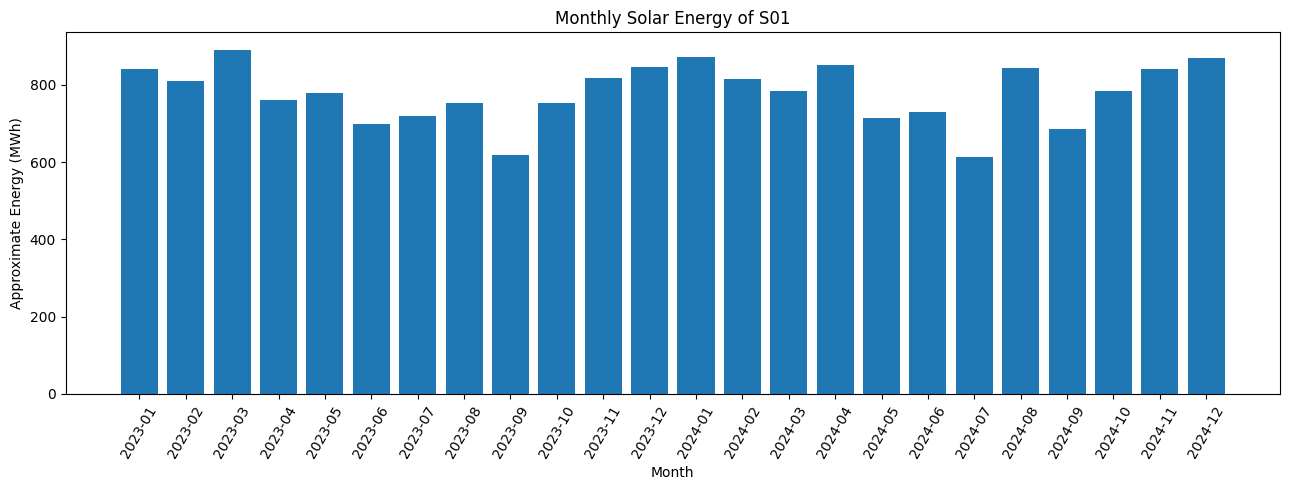

In [ ]:
energy_df = df_raw[["timestamp", "P"]].copy()

# Do not fill missing target values; only valid measurements contribute
energy_df["energy_kWh"] = energy_df["P"] * (5 / 60)
energy_df["month"] = energy_df["timestamp"].dt.to_period("M").astype(str)

monthly_energy = (
    energy_df
    .groupby("month", as_index=False)["energy_kWh"]
    .sum()
)

monthly_energy["energy_MWh"] = monthly_energy["energy_kWh"] / 1000

display(monthly_energy[["month", "energy_MWh"]])

monthly_energy.to_csv(
    OUTPUT_DIR / "table_04_monthly_energy.csv",
    index=False
)

plt.figure(figsize=(13, 5))
plt.bar(monthly_energy["month"], monthly_energy["energy_MWh"])
plt.xlabel("Month")
plt.ylabel("Approximate Energy (MWh)")
plt.title("Monthly Solar Energy of S01")
plt.xticks(rotation=60)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_04_monthly_energy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 2.7 Distribution of Power Generation

Solar power data contain many zero values at night. We show two distributions: one for all 24-hour observations and one limited to daytime hours (06:00–18:00). This also illustrates why percentage-based metrics such as MAPE become unstable near zero generation.

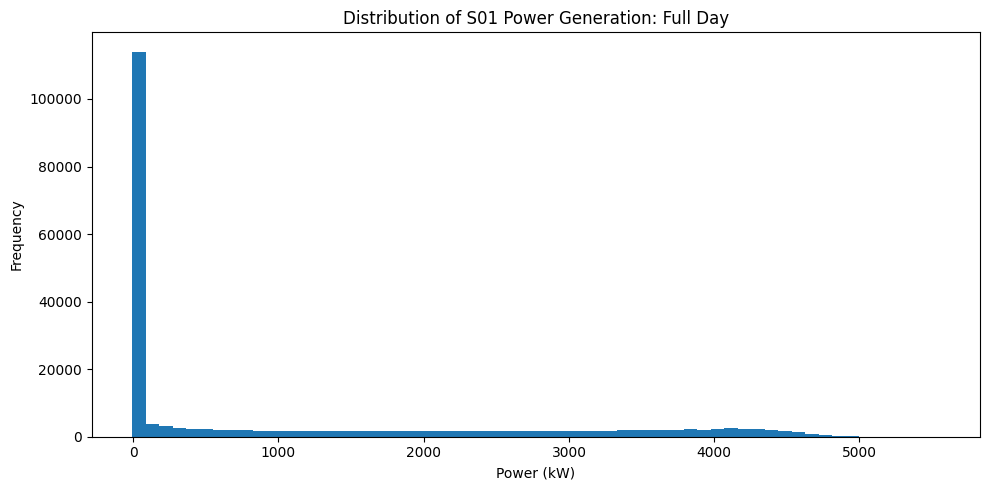

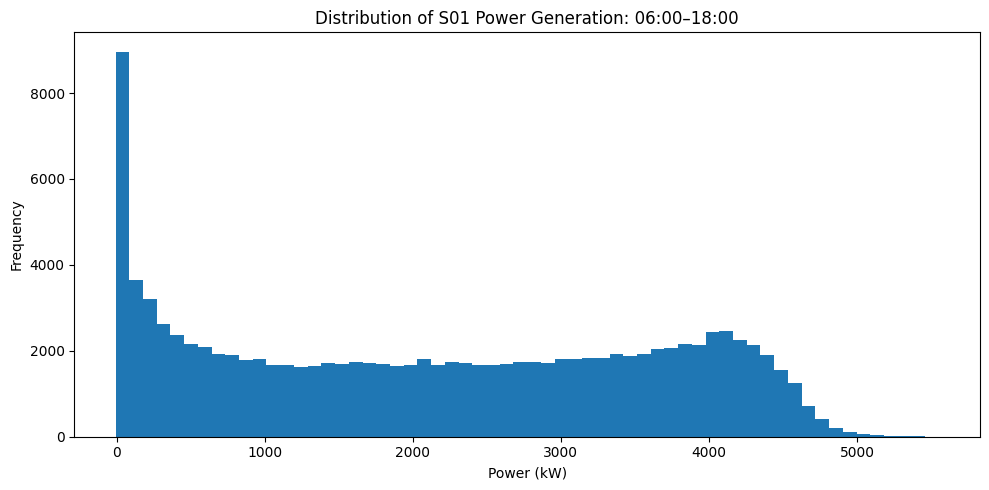

Full-day skewness: 1.0865
Daylight skewness: 0.0675


In [ ]:
hour_decimal = (
    df_raw["timestamp"].dt.hour +
    df_raw["timestamp"].dt.minute / 60
)

daylight_mask = (hour_decimal >= 6) & (hour_decimal < 18)

plt.figure(figsize=(10, 5))
plt.hist(df_raw["P"].dropna(), bins=60)
plt.xlabel("Power (kW)")
plt.ylabel("Frequency")
plt.title("Distribution of S01 Power Generation: Full Day")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_05_power_distribution_full_day.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(df_raw.loc[daylight_mask, "P"].dropna(), bins=60)
plt.xlabel("Power (kW)")
plt.ylabel("Frequency")
plt.title("Distribution of S01 Power Generation: 06:00–18:00")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_06_power_distribution_daylight.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Full-day skewness:", round(df_raw["P"].skew(), 4))
print(
    "Daylight skewness:",
    round(df_raw.loc[daylight_mask, "P"].skew(), 4)
)

## 2.8 Outlier Examination

Boxplots are used to visually inspect each key variable for unusual observations. Points beyond the whiskers indicate values that fall outside the typical interquartile range.

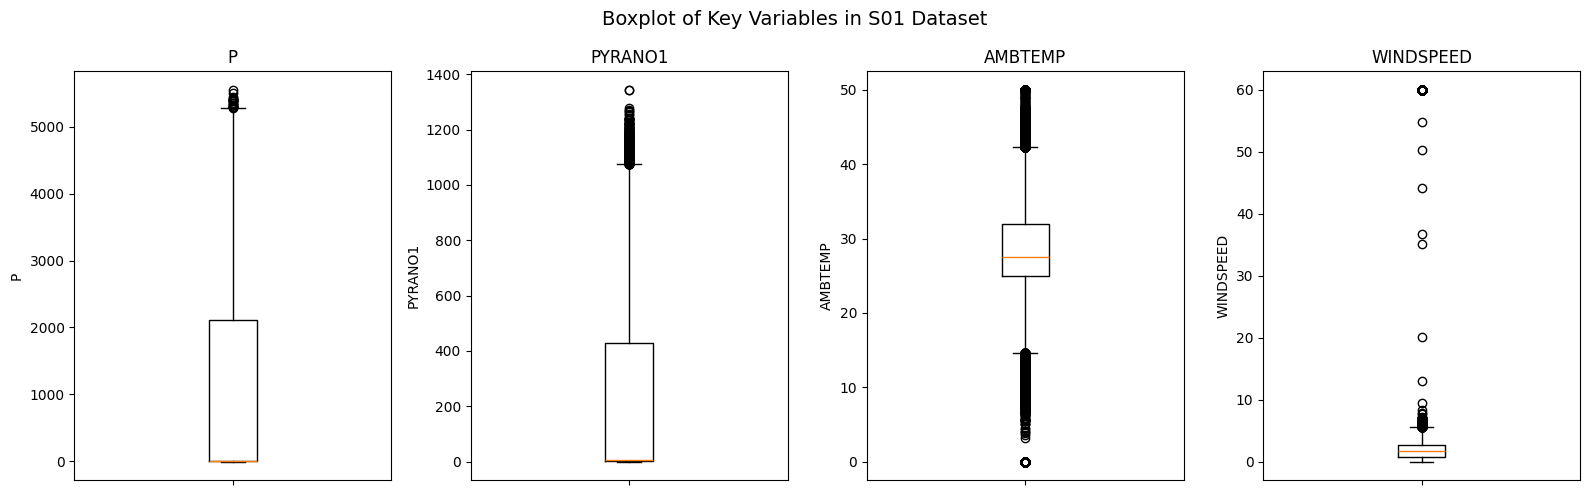

Observations beyond IQR fences (potential outliers):
--------------------------------------------------
  P           : 22 observations (0.01%)
  PYRANO1     : 636 observations (0.30%)
  AMBTEMP     : 7,190 observations (3.42%)
  WINDSPEED   : 21,839 observations (10.38%)


In [ ]:
key_vars = ["P", "PYRANO1", "AMBTEMP", "WINDSPEED"]

fig, axes = plt.subplots(1, len(key_vars), figsize=(16, 5))

for ax, col in zip(axes, key_vars):
    ax.boxplot(df_raw[col].dropna(), vert=True)
    ax.set_title(col)
    ax.set_ylabel(col)
    ax.set_xticklabels([""])

plt.suptitle("Boxplot of Key Variables in S01 Dataset", fontsize=14)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_06_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Count observations beyond the IQR fences for each variable
print("Observations beyond IQR fences (potential outliers):")
print("-" * 50)
for col in key_vars:
    vals = df_raw[col].dropna()
    q1 = vals.quantile(0.25)
    q3 = vals.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_outliers = ((vals < lower) | (vals > upper)).sum()
    print(f"  {col:12s}: {n_outliers:,} observations ({n_outliers / len(vals) * 100:.2f}%)")

## 2.9 Data Distribution and Skewness

We compute the skewness of each variable to understand the shape of its distribution. Positive skewness indicates a right-tailed distribution, while values near zero suggest approximate symmetry.

In [ ]:
skewness = df_raw[sensor_cols].skew().round(3)
kurtosis = df_raw[sensor_cols].kurtosis().round(3)

dist_summary = pd.DataFrame({
    "skewness": skewness,
    "kurtosis": kurtosis
})

display(dist_summary)

dist_summary.to_csv(
    OUTPUT_DIR / "table_04_skewness_kurtosis.csv"
)

print("\nInterpretation:")
for col in sensor_cols:
    sk = skewness[col]
    if abs(sk) < 0.5:
        shape = "approximately symmetric"
    elif sk > 0:
        shape = "right-skewed (positively skewed)"
    else:
        shape = "left-skewed (negatively skewed)"
    print(f"  {col:12s}: {sk:+.3f} — {shape}")

,skewness,kurtosis
PVTEMP1,0.923,-0.206
PVTEMP2,0.920,-0.206
AMBTEMP,0.268,2.466
PYRANO1,1.159,-0.106
PYRANO2,1.155,-0.120
WINDSPEED,2.600,4.797
P,1.086,-0.345



Interpretation:
  PVTEMP1     : +0.923 — right-skewed (positively skewed)
  PVTEMP2     : +0.920 — right-skewed (positively skewed)
  AMBTEMP     : +0.268 — approximately symmetric
  PYRANO1     : +1.159 — right-skewed (positively skewed)
  PYRANO2     : +1.155 — right-skewed (positively skewed)
  WINDSPEED   : +2.600 — right-skewed (positively skewed)
  P           : +1.086 — right-skewed (positively skewed)


## 2.10 Solar Irradiance vs. Power Generation

We investigate the relationship between measured solar irradiance (PYRANO1) and PV power output. A reproducible sample is used for plotting when the dataset is large.

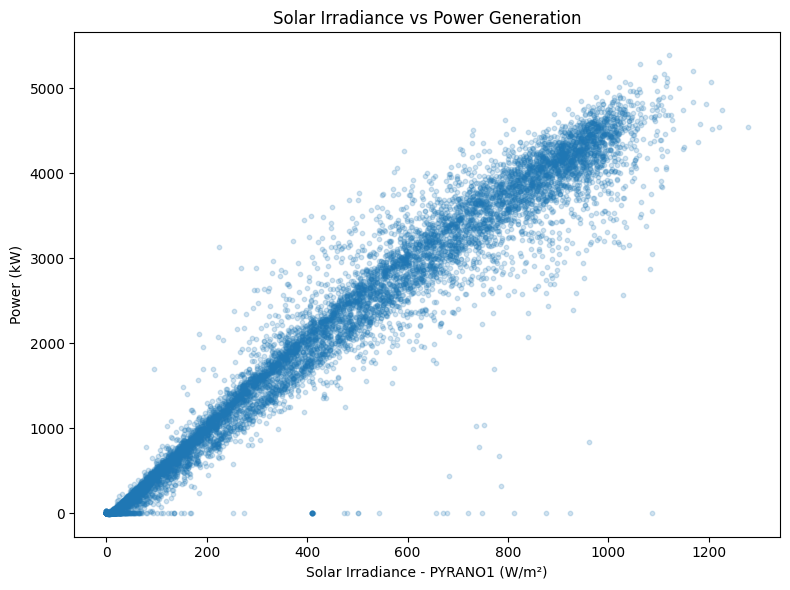

Pearson correlation between PYRANO1 and P: 0.9871


In [ ]:
scatter_df = df_raw[["PYRANO1", "P"]].dropna()

if len(scatter_df) > 20000:
    scatter_df = scatter_df.sample(
        20000,
        random_state=RANDOM_STATE
    )

plt.figure(figsize=(8, 6))
plt.scatter(
    scatter_df["PYRANO1"],
    scatter_df["P"],
    alpha=0.2,
    s=10
)
plt.xlabel("Solar Irradiance - PYRANO1 (W/m²)")
plt.ylabel("Power (kW)")
plt.title("Solar Irradiance vs Power Generation")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_07_irradiance_vs_power.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

irradiance_corr = df_raw[["PYRANO1", "P"]].corr().iloc[0, 1]
print("Pearson correlation between PYRANO1 and P:", round(irradiance_corr, 4))

## 2.11 Correlation Matrix


,PVTEMP1,PVTEMP2,AMBTEMP,PYRANO1,PYRANO2,WINDSPEED,P
PVTEMP1,1.000,1.000,0.626,0.935,0.932,0.015,0.917
PVTEMP2,1.000,1.000,0.627,0.935,0.932,0.017,0.918
AMBTEMP,0.626,0.627,1.000,0.472,0.466,0.070,0.452
PYRANO1,0.935,0.935,0.472,1.000,0.999,-0.005,0.987
PYRANO2,0.932,0.932,0.466,0.999,1.000,0.001,0.988
WINDSPEED,0.015,0.017,0.070,-0.005,0.001,1.000,-0.002
P,0.917,0.918,0.452,0.987,0.988,-0.002,1.000


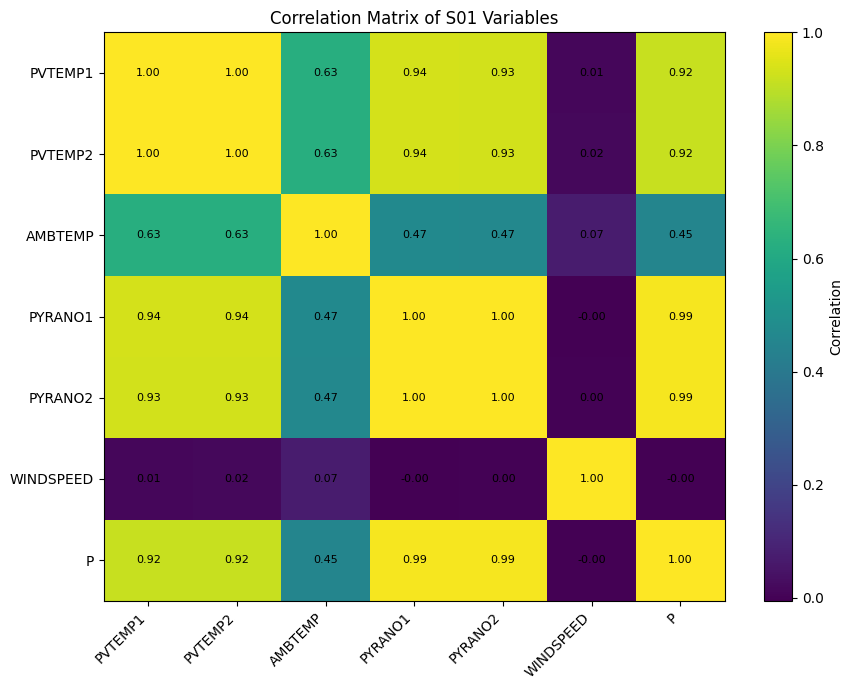

In [ ]:
corr_matrix = df_raw[sensor_cols].corr()

display(corr_matrix.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_matrix.values, aspect="auto")

ax.set_xticks(np.arange(len(corr_matrix.columns)))
ax.set_yticks(np.arange(len(corr_matrix.index)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right")
ax.set_yticklabels(corr_matrix.index)

for i in range(len(corr_matrix.index)):
    for j in range(len(corr_matrix.columns)):
        ax.text(
            j, i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation Matrix of S01 Variables")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_08_correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 2.12 Preliminary Findings Summary

A concise numerical summary of the key findings from the EDA, used as reference when writing the Preliminary Results section of the proposal.

In [ ]:
valid_p = df_raw["P"].dropna()

summary = {
    "Study period": (
        f"{df_raw['timestamp'].min().date()} to "
        f"{df_raw['timestamp'].max().date()}"
    ),
    "5-min records": len(df_raw),
    "Unique calendar days": df_raw["timestamp"].dt.date.nunique(),
    "Duplicate timestamps": int(df_raw["timestamp"].duplicated().sum()),
    "Missing P values": int(df_raw["P"].isna().sum()),
    "Mean power (kW)": valid_p.mean(),
    "Maximum observed power (kW)": valid_p.max(),
    "Power skewness": valid_p.skew(),
    "PYRANO1-P correlation": irradiance_corr
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Item", "Value"]
)

display(summary_df)

summary_df.to_csv(
    OUTPUT_DIR / "table_05_preliminary_summary.csv",
    index=False
)

print("\n--- Proposal writing helper ---")
print(
    f"The dataset covers {summary['Study period']} and contains "
    f"{summary['5-min records']:,} five-minute records."
)
print(
    f"The observed correlation between PYRANO1 and power generation is "
    f"{summary['PYRANO1-P correlation']:.4f}."
)
print(
    f"The maximum observed power is "
    f"{summary['Maximum observed power (kW)']:.2f} kW."
)
print("\nUse these statements only after checking the EDA figures above.")

,Item,Value
0,Study period,2023-01-01 to 2024-12-31
1,5-min records,210528
2,Unique calendar days,731
3,Duplicate timestamps,0
4,Missing P values,335
5,Mean power (kW),1067.96372
6,Maximum observed power (kW),5552.26
7,Power skewness,1.08646
8,PYRANO1-P correlation,0.987053



--- Proposal writing helper ---
The dataset covers 2023-01-01 to 2024-12-31 and contains 210,528 five-minute records.
The observed correlation between PYRANO1 and power generation is 0.9871.
The maximum observed power is 5552.26 kW.

Use these statements only after checking the EDA figures above.


# 3. Data Preprocessing

The original 5-minute measurements are aggregated into 15-minute intervals to align with PEA's standard metering resolution. For each 15-minute window, the mean of the available 5-minute readings is computed.

For the target variable (power generation), an interval is set to missing if fewer than three valid 5-minute measurements are present, since a reliable actual value is required for model evaluation.

In [ ]:
df = df_raw.copy()
df = df.drop_duplicates(subset="timestamp", keep="first")
df = df.sort_values("timestamp")
df = df.set_index("timestamp")

numeric_cols = [
    "PVTEMP1",
    "PVTEMP2",
    "AMBTEMP",
    "PYRANO1",
    "PYRANO2",
    "WINDSPEED",
    "P"
]

# Note: raw P is kept as is (small negative values near sunrise/sunset are preserved).
# Clipping to the 0-6,000 kW operating range is decided at the modelling stage.

# Mean values in each 15-min window
df_15 = df[numeric_cols].resample("15min").mean()

# Count how many valid 5-min observations contributed to each 15-min P value
p_count = df["P"].resample("15min").count()
df_15["P_count_5min"] = p_count

# Strict target: need all 3 expected measurements
df_15.loc[df_15["P_count_5min"] < 3, "P"] = np.nan

print("15-min rows:", f"{len(df_15):,}")
print("Incomplete target intervals:", int((df_15["P_count_5min"] < 3).sum()))
print("Missing 15-min target P:", int(df_15["P"].isna().sum()))

display(df_15.head())

# Round to avoid floating-point artifacts such as 15.316666666666668
# (Excel can flag these long values as text)
df_15 = df_15.round(4)

df_15.to_csv(
    OUTPUT_DIR / "S01_2023_2024_15min_processed.csv"
)

15-min rows: 70,176
Incomplete target intervals: 120
Missing 15-min target P: 120


,PVTEMP1,PVTEMP2,AMBTEMP,PYRANO1,PYRANO2,WINDSPEED,P,P_count_5min
timestamp,,,,,,,,
2023-01-01 00:00:00,20.303333,20.633333,21.040000,0.606667,0.416667,3.683333,0.0,3
2023-01-01 00:15:00,19.956667,20.286667,20.783333,0.613333,0.420000,3.240000,0.0,3
2023-01-01 00:30:00,19.783333,20.110000,20.530000,0.620000,0.420000,2.900000,0.0,3
2023-01-01 00:45:00,19.600000,19.933333,20.266667,0.630000,0.416667,3.236667,0.0,3
2023-01-01 01:00:00,19.480000,19.780000,19.983333,0.633333,0.406667,3.286667,0.0,3


### 15-Minute Completeness by Day

A complete day should contain 96 valid 15-minute target intervals. We check how many days meet this criterion.

In [ ]:
daily_completeness = (
    df_15["P"]
    .notna()
    .groupby(df_15.index.date)
    .sum()
    .rename("valid_intervals")
    .to_frame()
)

daily_completeness["complete_96"] = (
    daily_completeness["valid_intervals"] == 96
)

print(
    "Complete days:",
    int(daily_completeness["complete_96"].sum()),
    "/",
    len(daily_completeness)
)

display(daily_completeness["valid_intervals"].value_counts().sort_index().tail(15))

Complete days: 722 / 731


valid_intervals
53      1
71      2
85      1
92      2
93      2
94      1
96    722
Name: count, dtype: int64

In [ ]:
#  Day completeness with flags
daily_completeness["low_completeness"] = daily_completeness["valid_intervals"] < 80

complete_days = int(daily_completeness["complete_96"].sum())
low_days = int(daily_completeness["low_completeness"].sum())
partial_days = int(
    (~daily_completeness["complete_96"] & ~daily_completeness["low_completeness"]).sum()
)
total_days = len(daily_completeness)

print("Day-level completeness summary")
print("=" * 50)
print(f"  Complete (96/96):     {complete_days}")
print(f"  Partial (80–95):      {partial_days}")
print(f"  Low (<80 intervals):  {low_days}")
print(f"  Total days:           {total_days}")

# Show all non-complete days
incomplete = daily_completeness[~daily_completeness["complete_96"]].copy()
incomplete.index = pd.to_datetime(incomplete.index)
print(f"\n{len(incomplete)} days with fewer than 96 valid intervals:")
display(incomplete.sort_values("valid_intervals"))

# ── Calendar heatmap: valid P intervals per day ──
import matplotlib.dates as mdates

heatmap_df = daily_completeness.copy()
heatmap_df.index = pd.to_datetime(heatmap_df.index)

fig, ax = plt.subplots(figsize=(14, 5))
ax.scatter(
    heatmap_df.index,
    heatmap_df["valid_intervals"],
    c=heatmap_df["valid_intervals"],
    cmap="RdYlGn",
    vmin=0, vmax=96,
    s=8,
    edgecolors="none"
)
ax.axhline(96, color="green", linewidth=0.5, linestyle="--", alpha=0.5)
ax.axhline(80, color="red", linewidth=0.5, linestyle="--", alpha=0.5)
ax.set_xlabel("Date")
ax.set_ylabel("Valid 15-min P intervals")
ax.set_title("Daily Completeness of Target Variable (P)")
ax.set_ylim(-2, 100)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure_09_daily_completeness.png", dpi=150)
plt.show()